![mlp](../../assets/char_mlp_architecture_en.svg)
Fully Connected Neural Network

In [3]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt # for making figures
%matplotlib inline

In [4]:
# read in all the words
words = open('../../data/names.txt', 'r').read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [5]:
# build the vocabulary of characters and mappings to/from integers
chars = sorted(list(set("".join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
V = len(itos)

In [6]:
device = torch.device(
  "cuda" if torch.cuda.is_available()
  else ("mps" if torch.backends.mps.is_available() else "cpu")
)
device

device(type='mps')

In [7]:
# build the dataset
n = 3 # n: how many characters do we take to predict the next one?

def build_dataset(words):  
  X, Y = [], []
  
  for w in words:
    context = [0] * n
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      context = context[1:] + [ix] # crop and append

  X = torch.tensor(X)
  Y = torch.tensor(Y)
  print(X.shape, Y.shape)
  return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr,  Ytr  = build_dataset(words[:n1])     # 80%
Xdev, Ydev = build_dataset(words[n1:n2])   # 10%
Xte,  Yte  = build_dataset(words[n2:])     # 10%

Xtr, Ytr = Xtr.to(device), Ytr.to(device)
Xdev, Ydev = Xdev.to(device), Ydev.to(device)
Xte, Yte = Xte.to(device), Yte.to(device)

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [8]:
# MLP revisited
m = 10 # the dimensionality of the character embedding vectors
h = 200 # the number of neurons in the hidden layer of the MLP
g = torch.Generator(device= device).manual_seed(2147483647) # for reproducibility
C  = torch.randn((V, m), device= device, generator=g) # shape(27,10)
W1 = torch.randn((m * n, h), device= device, generator=g) * (5/3)/(m * n)**2 # kaiming init
b1 = torch.randn(h, device= device, generator=g) * 0.01
W2 = torch.randn((h, V), device= device, generator=g) * 0.1 # shrink logits towards 0
b2 = torch.randn(V, device= device, generator=g) * 0 # shrink logits towards 0
bngains = torch.ones((1, h), device= device)
bnbias = torch.zeros((1, h), device= device)
bmeans_running = torch.zeros(1, h)
bstds_running = torch.ones(1, h)

parameters = [C, W1, W2, b1, b2, bngains, bnbias]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
  p.requires_grad = True

12297


In [6]:
# max_iterations = 200000
# batch_size = 32
# indices = torch.randint(len(Xtr), (batch_size,),)
# embed = C[Xtr[indices]]
# print(C.shape)
# print(Xtr.shape)
# print(indices.shape)
# print(Xtr[indices].shape)
# print(embed.shape)

In [ ]:
max_iterations = 200000
batch_size = 32
lossi = []

for i in range(max_iterations):
  # mini-batch
  indices = torch.randint(0, len(Xtr), (batch_size,), device= device, generator=g)
  embed = C[Xtr[indices]]# (32, 3, 10)
  x = embed.view(embed.shape[0], -1) # concate vectors

  # linear layer
  # hpreact = x @ W1 + b1 # hidden layer preactivations
  hpreact = x @ W1 # hidden layer preactivations

  # batch norm layer
  bnmeani = hpreact.mean(dim=0, keepdim=True)
  bnstdi = hpreact.std(dim=0, keepdim=True)
  hpreact = bngains * (hpreact - bnmeani) / bnstdi + bnbias

  # easily track the accuracy of the model while training
  with torch.no_grad():
    bmeans_running = 0.999 * bmeans_running + 0.001 * bnmeani
    bstds_running = 0.999 * bstds_running + 0.001 * bstds_running

  # non-linearity
  h_output = torch.tanh(hpreact) # activations
  logits = h_output @ W2 + b2 # output layer
  loss = F.cross_entropy(logits, Ytr[indices]) # loss function
  for p in parameters:
    p.grad = None

  loss.backward()

  lr = 0.1 if i < 100000 else 0.01
  for p in parameters:
    p.data += -lr * p.grad

  if i % 10000 == 0:
    print(f"{i: 7d}/{max_iterations: 7d}, {loss.item(): 4f}")
  lossi.append(loss.log10().item())

In [ ]:
class Linear:
  def __init__(self, fan_in, fan_out, bias = True, device = device):
    self.weight = torch.randn((fan_in, fan_out), generator=g, device= device) / fan_in**0.5
    self.bias = torch.zeros(fan_out, device= device) if bias else None

  def __call__(self, x):
    self.out = x @ self.weight
    if self.bias is not None:
      self.out += self.bias
    return self.out

  def parameters(self):
    return [self.weight] + self.bias if self.bias else []

In [ ]:
class BatchNorm:
  def __init__(self, dim, eps=1e-05, momentum=0.1, track_running_stats=True, 
               training = True,bias = True, device = device):
    self.eps = eps
    self.momentum = momentum
    self.training = training
    self.gamma = torch.ones(dim, device = device)
    self.beta = torch.zeros(dim, device = device) if bias else None
    if track_running_stats:
      self.tracking = True
      # buffers
      self.moving_means = torch.zeros(dim, device=device)
      self.moving_variance = torch.ones(dim, device=device)

  def __call__(self, x):
    if not self.training:
      x_mean = self.moving_means
      x_var = self.moving_variance
    else:
      # inference
      x_mean = x.mean(dim = 0, keep_dim = True)
      x_var = x.var(dim = 0, keep_dim = True)

    x_hat = (x - x_mean) / torch.sqrt(x_var + self.eps) 
    self.out = x_hat * self.gamma + self.beta

    if self.tracking:
      with torch.no_grad:
        self.moving_means = (1 - self.momentum) * self.moving_means + self.momentum * x_mean
        self.moving_variance = (1 - self.momentum) * self.moving_variance + self.momentum * x_var
    return self.out

  def parameters(self):
    return [self.gamma, self.beta]

In [ ]:
class Tanh():
  def __call__(self, x):
    self.tanh = torch.tanh(x)
    return self.tanh
  def parameters(self):
    return []

In [ ]:
m = 10 # the dimensionality of the character embedding vectors
n_hidden = 100 # the number of neurons in the hidden layer of the MLP
g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((V, m), generator= g, device= device)

layers = [
  Linear(n * m, n_hidden, bias=False), BatchNorm(n_hidden), Tanh(),
  Linear(n_hidden, n_hidden, bias=False), BatchNorm(n_hidden), Tanh(),
  Linear(n_hidden, n_hidden, bias=False), BatchNorm(n_hidden), Tanh(),
  Linear(n_hidden, n_hidden, bias=False), BatchNorm(n_hidden), Tanh(),
  Linear(n_hidden, n_hidden, bias=False), BatchNorm(n_hidden), Tanh(),
  Linear(n_hidden, V, bias=False), BatchNorm(V)
]

parameters = [C] + [layer.parameters for layer in layers]
for p in parameters:
  p.requires_grad = True

In [ ]:
max_iterations = 200000
batch_size = 32
lossi = []

for i in range(max_iterations):
  # mini-batch
  indices = torch.randint(0, len(Xtr), (batch_size,), device= device, generator=g)
  embed = C[Xtr[indices]]# (32, 3, 10)
  x = embed.view(embed.shape[0], -1) # concate vectors

  # forward pass
  for layer in layers:
    x = layer(x)

  loss = F.cross_entropy(x, Ytr[indices])

  # backward pass
  for layer in layers:
    layer.out.retain_grad()
  for p in parameters:
    p.grad = None

  loss.backward()

  lr = 0.1 if i < 150000 else 0.01
  for p in parameters:
    p.data += -lr * p.grad

  if i % 10000 == 0:
    print(f"{i: 7d}/{max_iterations: 7d}, {loss.item(): 4f}")
  lossi.append(loss.log10().item())

  if i >= 1000:
    break

      0/ 200000,  3.656157
  10000/ 200000,  2.244370
  20000/ 200000,  2.090707
  30000/ 200000,  2.322083
  40000/ 200000,  2.115129
  50000/ 200000,  1.977116
  60000/ 200000,  2.222754
  70000/ 200000,  2.333167
  80000/ 200000,  2.092371
  90000/ 200000,  2.381437
 100000/ 200000,  1.959906
 110000/ 200000,  2.025048
 120000/ 200000,  2.568456
 130000/ 200000,  2.500013
 140000/ 200000,  1.666131
 150000/ 200000,  2.007704
 160000/ 200000,  2.040497
 170000/ 200000,  2.176283
 180000/ 200000,  1.690645
 190000/ 200000,  2.529451


In [ ]:
'''
Problem 1: Initial loss problem

before initial loss fixing:
0.2332,  10.7383, -11.3327, -11.8236,  -8.7257, -17.2157,  -0.3718,
         32.1403,  -7.2298,  17.0199,  -0.3521,   0.3299, -12.4953, -26.9725,
         20.2075,   7.7739,  -0.7175,  34.3389,   2.3970,  -2.3391,   1.5995,
         -0.1784,  12.4380,   4.7147,  15.4891,   8.9986,  -1.2054

after
0.0460,  1.0106, -1.1204, -1.1039, -0.8728, -1.6923,  0.0556,  3.2457,
        -0.6150,  1.5022, -0.0435,  0.0679, -1.2023, -2.8340,  1.9011,  0.7202,
         0.0226,  3.5731,  0.1978, -0.3504,  0.1376,  0.1158,  1.0504,  0.3983,
         1.5369,  1.0069, -0.1902
'''
logits[0]

tensor([  0.2332,  10.7383, -11.3327, -11.8236,  -8.7257, -17.2157,  -0.3718,
         32.1403,  -7.2298,  17.0199,  -0.3521,   0.3299, -12.4953, -26.9725,
         20.2075,   7.7739,  -0.7175,  34.3389,   2.3970,  -2.3391,   1.5995,
         -0.1784,  12.4380,   4.7147,  15.4891,   8.9986,  -1.2054],
       device='cuda:0', grad_fn=<SelectBackward0>)

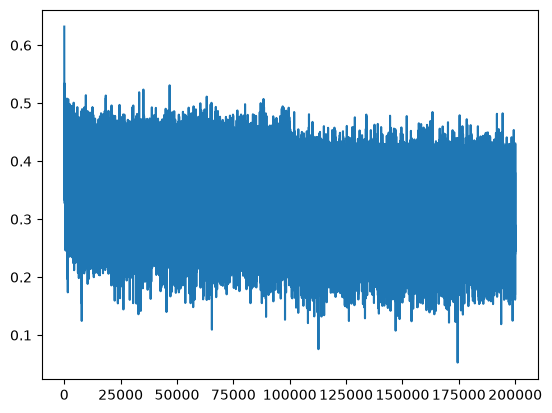

In [ ]:
# 0/200000: loss 28.586521 (expected ≈ 3.30 = -log(1/27)), so the curve looks like a hockey stick
# early iterations just shrink the overconfident logits instead of learning
plt.plot(lossi) 

In [ ]:
# if the model knows nothing then prob for each word should be 1/V 
print(-torch.tensor((1/27)).log())
# here idx2 has samll logit -> small prob, model thinks idx2 is unlikely to occur
# when idx2 occurs it contributes to a high loss val
logits = torch.tensor((1.0, -5.0, 0.0, 10.0)) 
probs = torch.softmax(logits, dim=0)
print(probs)
-probs[2].log() 

tensor(3.2958)
tensor([1.2339e-04, 3.0585e-07, 4.5392e-05, 9.9983e-01])


tensor(10.0002)

(array([2299.,  177.,  111.,   68.,   69.,   56.,   39.,   36.,   40.,
          32.,   33.,   38.,   32.,   23.,   16.,   18.,   25.,   17.,
          17.,   15.,   19.,   25.,   21.,   20.,   18.,   17.,   20.,
          20.,   13.,   19.,   21.,   20.,   25.,   22.,   20.,   15.,
          14.,   16.,   35.,   35.,   24.,   38.,   32.,   48.,   40.,
          69.,   80.,   93.,  174., 2226.]),
 array([-1.  , -0.96, -0.92, -0.88, -0.84, -0.8 , -0.76, -0.72, -0.68,
        -0.64, -0.6 , -0.56, -0.52, -0.48, -0.44, -0.4 , -0.36, -0.32,
        -0.28, -0.24, -0.2 , -0.16, -0.12, -0.08, -0.04,  0.  ,  0.04,
         0.08,  0.12,  0.16,  0.2 ,  0.24,  0.28,  0.32,  0.36,  0.4 ,
         0.44,  0.48,  0.52,  0.56,  0.6 ,  0.64,  0.68,  0.72,  0.76,
         0.8 ,  0.84,  0.88,  0.92,  0.96,  1.  ]),
 <BarContainer object of 50 artists>)

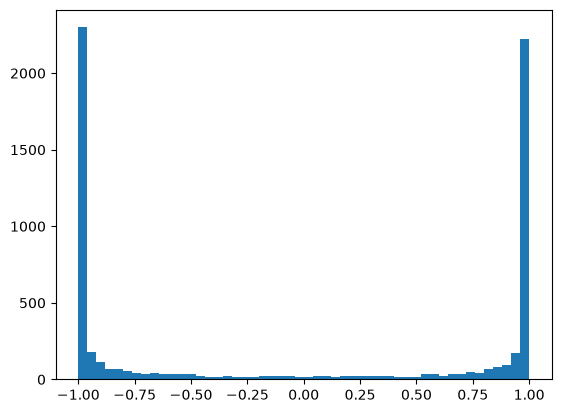

In [ ]:
'''
Probelm 2: Saturated tanh
derivative of tanh = 1 - tanh^2, tanh -> 1, derivative -> 0
bp: derivative of tanh = (1 - tanh^2) * out.grad = 0
'''
plt.hist(h_output.view(-1).tolist(), 50) # most concentrated on +-1

(array([215., 187., 198., 156., 169., 136., 124., 153., 125., 120., 130.,
        133., 116.,  87., 148., 117.,  96., 111., 112., 107., 110.,  95.,
         93.,  83.,  97., 112.,  91.,  94.,  89.,  98.,  86., 124.,  91.,
         96.,  92., 121., 100., 109., 119.,  89., 141., 120., 145., 131.,
        156., 167., 176., 181., 229., 225.]),
 array([-9.99332428e-01, -9.59365253e-01, -9.19398079e-01, -8.79430904e-01,
        -8.39463730e-01, -7.99496555e-01, -7.59529381e-01, -7.19562206e-01,
        -6.79595032e-01, -6.39627857e-01, -5.99660683e-01, -5.59693508e-01,
        -5.19726334e-01, -4.79759159e-01, -4.39791985e-01, -3.99824810e-01,
        -3.59857635e-01, -3.19890461e-01, -2.79923286e-01, -2.39956112e-01,
        -1.99988937e-01, -1.60021763e-01, -1.20054588e-01, -8.00874138e-02,
        -4.01202393e-02, -1.53064728e-04,  3.98141098e-02,  7.97812843e-02,
         1.19748459e-01,  1.59715633e-01,  1.99682808e-01,  2.39649982e-01,
         2.79617157e-01,  3.19584332e-01,  3.59551

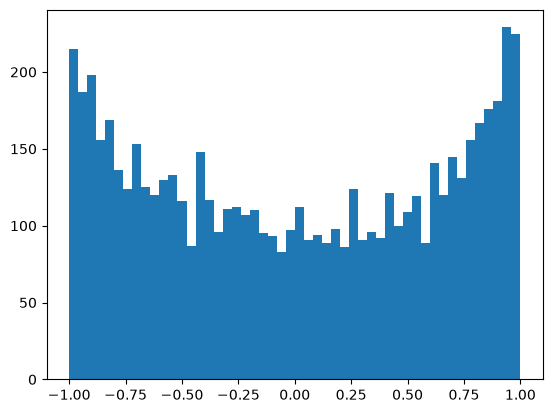

In [ ]:
plt.hist(h_output.view(-1).tolist(), 50) # more evenly distributed

(array([  1.,   0.,   1.,   7.,   4.,   6.,   8.,   7.,  22.,  17.,  17.,
         39.,  49.,  66.,  75.,  89., 135., 203., 171., 214., 293., 296.,
        336., 382., 396., 379., 363., 378., 337., 299., 306., 254., 232.,
        199., 195., 145., 113.,  89.,  77.,  66.,  42.,  33.,  17.,  11.,
         10.,   7.,   9.,   1.,   2.,   2.]),
 array([-20.64251137, -19.85227478, -19.06203819, -18.27180161,
        -17.48156502, -16.69132843, -15.90109184, -15.11085526,
        -14.32061867, -13.53038208, -12.74014549, -11.94990891,
        -11.15967232, -10.36943573,  -9.57919914,  -8.78896255,
         -7.99872597,  -7.20848938,  -6.41825279,  -5.6280162 ,
         -4.83777962,  -4.04754303,  -3.25730644,  -2.46706985,
         -1.67683327,  -0.88659668,  -0.09636009,   0.6938765 ,
          1.48411308,   2.27434967,   3.06458626,   3.85482285,
          4.64505943,   5.43529602,   6.22553261,   7.0157692 ,
          7.80600578,   8.59624237,   9.38647896,  10.17671555,
         10.966952

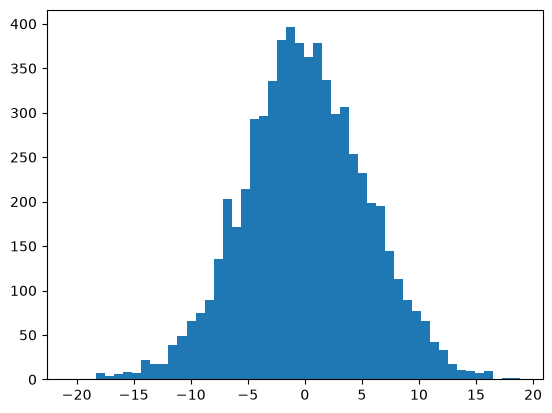

In [23]:
plt.hist(hpreact.view(-1).tolist(), 50)

(array([  2.,   1.,   3.,   1.,   3.,   7.,   9.,  16.,  18.,  25.,  23.,
         42.,  57.,  54.,  82., 138., 141., 178., 212., 237., 282., 342.,
        360., 378., 407., 369., 343., 360., 352., 286., 289., 258., 237.,
        191., 149., 128., 104.,  92.,  66.,  49.,  39.,  16.,  16.,  15.,
          8.,   6.,   6.,   1.,   0.,   2.]),
 array([-4.00233603, -3.84601885, -3.68970168, -3.53338451, -3.37706734,
        -3.22075016, -3.06443299, -2.90811582, -2.75179865, -2.59548148,
        -2.4391643 , -2.28284713, -2.12652996, -1.97021279, -1.81389562,
        -1.65757844, -1.50126127, -1.3449441 , -1.18862693, -1.03230976,
        -0.87599258, -0.71967541, -0.56335824, -0.40704107, -0.2507239 ,
        -0.09440672,  0.06191045,  0.21822762,  0.37454479,  0.53086196,
         0.68717914,  0.84349631,  0.99981348,  1.15613065,  1.31244782,
         1.468765  ,  1.62508217,  1.78139934,  1.93771651,  2.09403368,
         2.25035086,  2.40666803,  2.5629852 ,  2.71930237,  2.87561954,
 

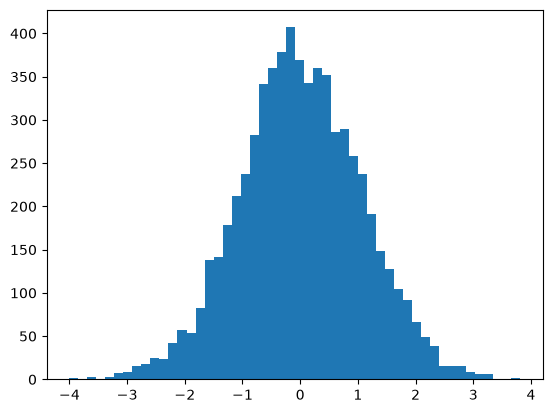

In [ ]:
# after adjusting w1 and b1, hpreact vals are more close to 0
plt.hist(hpreact.view(-1).tolist(), 50)

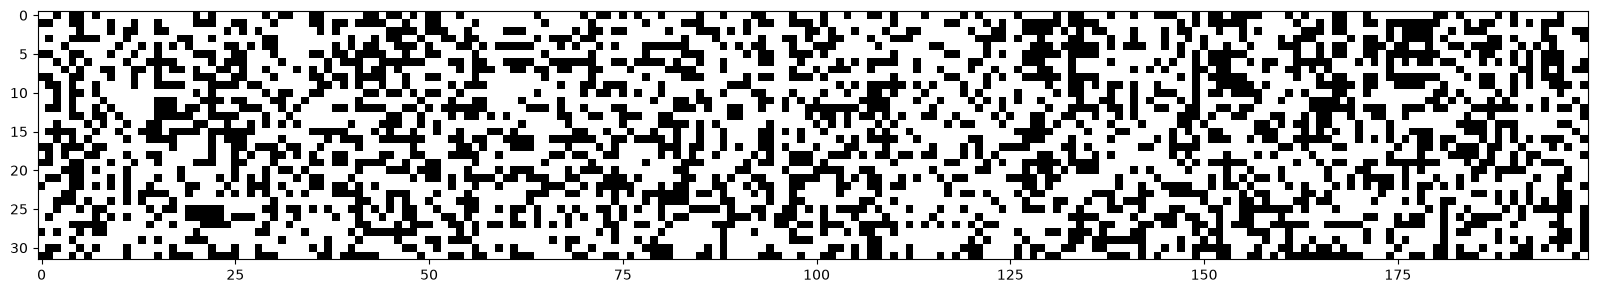

In [ ]:
'''
Rows: 32 samples, columns: 200 hidden neurons.
White = saturated (|tanh| > 0.99): local derivative 1 - t^2 ≈ 0, so the gradient
flowing back through this neuron for this sample is ≈ 0 and backprop is cut off there.
An all-white column = dead neuron (saturated for every sample, never learns).
Dead neurons's weights and bias will never learn -> bad for training
'''
plt.figure(figsize=(20, 10))
plt.imshow(h_output.abs().cpu() > 0.99, cmap="gray", interpolation="nearest")

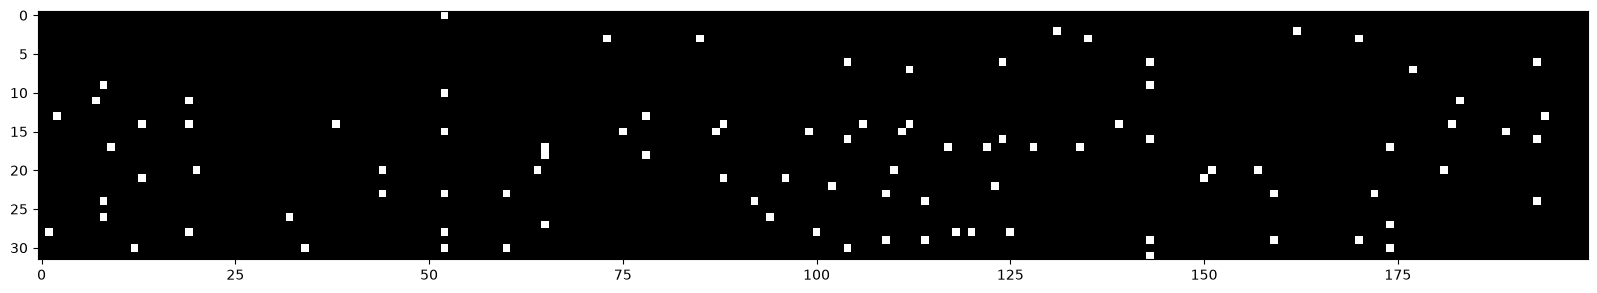

In [ ]:
# most black
plt.figure(figsize=(20, 10))
plt.imshow(h_output.abs().cpu() > 0.99, cmap="gray", interpolation="nearest")

![](./assets/activation_functions.png)
- tanh, sigmoid: both tails are flat → saturated on both sides
- ReLU: flat for x < 0 → saturated on the negative side only (can become a dead neuron)
- leaky ReLU: small nonzero slope for x < 0 → no flat region, not saturated

In [ ]:
# hyperbolic formula: x^2 - y^2 = 1, x = cosht, y = sinht
# tanh: sinht / cosht, x gets larger, y approximately equal to x, tanh -> 1
torch.tanh(torch.tensor(15.0)) 

tensor(1.)

tensor(1.0071)
tensor(0.9786)
tensor(0.0077) tensor(1.0071)
tensor(-0.0051) tensor(3.1142)


(array([7.02769423e-06, 0.00000000e+00, 1.40553885e-05, 2.10830827e-05,
        9.83877192e-05, 9.83877192e-05, 1.33526190e-04, 3.37329323e-04,
        4.84910902e-04, 8.92517167e-04, 1.32120651e-03, 2.67755150e-03,
        3.86523182e-03, 6.81686340e-03, 1.08296768e-02, 1.60090874e-02,
        2.40136312e-02, 3.55531051e-02, 4.72401606e-02, 6.48445346e-02,
        8.47258816e-02, 1.04290982e-01, 1.21979689e-01, 1.33455913e-01,
        1.38740739e-01, 1.28901967e-01, 1.17074358e-01, 9.84790792e-02,
        7.65105070e-02, 5.84423052e-02, 4.20818330e-02, 2.98325620e-02,
        2.02819255e-02, 1.32753144e-02, 8.41917768e-03, 5.42537994e-03,
        3.35923784e-03, 2.15047443e-03, 1.20173571e-03, 7.16824811e-04,
        3.86523182e-04, 2.03803133e-04, 1.89747744e-04, 6.32492480e-05,
        2.10830827e-05, 4.21661654e-05, 2.10830827e-05, 0.00000000e+00,
        0.00000000e+00, 7.02769423e-06]),
 array([-17.29234314, -16.58087223, -15.86940132, -15.15793041,
        -14.4464595 , -13.7349

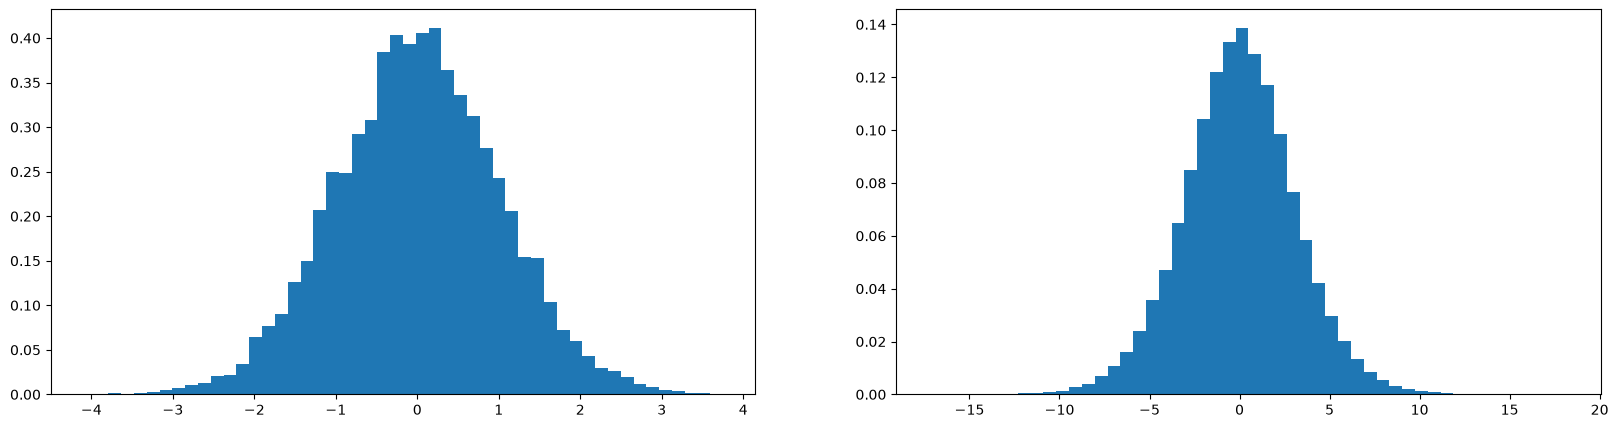

In [ ]:
'''
Problem 3: Init scale: "Kaiming init"
'''
x = torch.randn(1000, 10)
w = torch.randn(10, 200)
y = x @ w
print(x.mean(), x.std())
print(y.mean(), y.std())

plt.figure(figsize=(20, 5))
plt.subplot(121) # subplot(r, c, order)
plt.hist(x.view(-1).tolist(), 50, density=True)
plt.subplot(122)
plt.hist(y.view(-1).tolist(), 50, density=True)  

In [ ]:
# inference stage, algorithm2 at paper
# replace statistics
# another approach: maintain moving means and variance while training
with torch.no_grad():
  embed = C[Xtr]
  embedcat = embed.view(embed.shape[0], -1)
  hpreact = embedcat @ W1 + b1
  bnmean = hpreact.mean(dim=0, keepdim=True)
  bnstd = hpreact.std(dim=0, keepdim=True)

In [ ]:
@torch.no_grad()
def split_loss(data_set):
  losses = {
    "tr": (Xtr, Ytr),
    "dev": (Xdev, Ydev),
    "te": (Xte, Yte)
  }[data_set]

  embd = C[Xtr]
  x = embd.view(embd.shape[0], -1)
  hpreact = x @ W1 + b1
  # hpreact = bngains * (hpreact - hpreact.mean(dim=0, keepdim=True)) / hpreact.std(dim=0, keepdim=True) + bnbias
  hpreact = bngains * (hpreact - bnmean) / bnstd
  h_output = torch.tanh(hpreact)
  logits = h_output @ W2 + b2
  loss = F.cross_entropy(logits, Ytr)
  return loss.item()

'''
Original:
2.125293016433716
2.125293016433716

after fixing overconfidence softmax:
2.069462299346924
2.069462299346924

after fixing too saturated tanh:
2.0368764400482178
2.0368764400482178

kaiming init:
2.0965280532836914
2.0965280532836914

batch norm:
2.067913055419922
2.067913055419922

2.2327880859375
2.2327880859375
'''
print(split_loss("tr"))
print(split_loss("dev"))

2.2327880859375
2.2327880859375


In [ ]:
# Sampling
for i in range(20):
  output = []
  context = [0] * n
  embed = C[context]
  while True:
    embed = C[context]
    preact = embed.view(1, -1) @ W1 + b1
    h_output = torch.tanh(preact)
    logits = h_output @ W2 + b2
    probs = torch.softmax(logits, dim=1)
    idx = torch.multinomial(probs, 1, replacement= True, generator= g)
    output.append(idx.item())
    context = context[1:] + [idx.item()]
    if idx == 0:
      break
  print("".join(itos[idx] for idx in output))

lecaleiaha.
mahan.
aslin.
dasham.
kelia.
sadi.
ahna.
hada.
cecslvet.
mice.
jime.
hazel.
cavi.
dalen.
evyn.
karley.
kene.
kelen.
raide.
mundeli.
